<a href="https://colab.research.google.com/github/sabbirpuspo/PGCB-Demand-Aware-Smart-Grid-Optimization/blob/main/PGCB_Feasibility_%26_Independent_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PGCB_Feasibility & Independent Optimization

**IEEE working title:** *An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids*

**Purpose.** Earlier runs showed that the uncertainty-water-filling candidate achieved average peak reductions but sometimes exceeded hypothetical ex-post load-flexibility caps. In Phase 4, the exact-MWh LP used the candidate's chosen source and destination hours. That was not a fully independent comparison. This notebook repairs that methodological gap by adding an **unrestricted mixed-integer linear program (MILP)** which selects its own source/destination hours, subject to the **same candidate caps and exactly the same total energy shifted**.

**Research questions.** (1) Can the candidate outperform an independent full-hour exact-MWh optimum on *realized* peak reduction? (2) How do stronger historical demand-error margins affect feasibility versus peak reduction? (3) What can be concluded from paired daily comparisons under time dependence?

**Experimental design.** Reproduce the prior Ridge model from data through June 2022; form empirical hourly error envelopes using July–December 2022; evaluate 2023. Model selection and the 2023 outcomes were previously examined, so **all Phase 5 results are exploratory**. Do not describe 2023 as a new, untouched test. Separate 2024–2025 records remain outside this notebook.

**Source:** [PGCB Hourly Generation Dataset (Bangladesh), UCI 1175](https://archive.ics.uci.edu/dataset/1175/pgcb+hourly+generation+dataset+(bangladesh)), DOI https://doi.org/10.24432/C59P6V (CC BY 4.0). No customer-level flexible-load limits, installed hourly dispatchable capacity, or verified avoided shortages are supplied.

**Methodological distinction.** `UnrestrictedExactRobustMILP` and `UnrestrictedExactNominalMILP` solve an exact-MWh problem without reusing the candidate's chosen hours; `BudgetRobustLP` may shift *less* than the candidate under the same **maximum** movement budget. These answer different scientific questions. The standard LP/MILP result is mathematically optimal only for its *specified forecast proxy objective*, not for the unknown future realized demand.

**Related research already exists:** [Residential DSM optimization review, Energy Reports (2022)](https://doi.org/10.1016/j.egyr.2022.02.300), [Robust DSM, Journal of Building Engineering (2022)](https://doi.org/10.1016/j.jobe.2022.104486), [Distributionally robust HEMS and receding horizon, Frontiers in Energy (2020)](https://doi.org/10.1007/s11708-020-0665-4). These prevent us from claiming that water filling, demand shifting, or uncertainty-aware optimization is inherently new.

**What it does NOT establish:** physical real-world feasibility, energy savings (daily MWh is conserved), actual load-shedding prevention, a general confidence guarantee for quantile margins, or mathematical algorithmic novelty. A conservative `DomainFloorQ95` arm uses a 1,000 MW **research-data inclusion floor**, not a verified minimum operational demand. Its zero-violation property applies only inside this filtered dataset and hypothetical cap definition.

**How to run.** Upload the notebook to Google Colab, use **Runtime > Run all**, and authorize Google Drive. The original UCI workbook is reused from `MyDrive/PGCB_Demand_Optimization/data/`, or automatically downloaded if missing. All results go to a new timestamped `phase5_*` directory; previous experiments are untouched. CPU is sufficient. Every code cell is preceded by a description.

## 1. Runtime and libraries

Import the scientific libraries, including SciPy's HiGHS-based LP and MILP solvers. The exact-MWh independent-hour comparison uses binary decisions to ensure that any hour either donates or receives shifted demand, not both.

In [ ]:
import hashlib
import io
import json
import os
import platform
import shutil
import sys
import time
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scipy
import sklearn
from scipy.optimize import Bounds, LinearConstraint, linprog, milp
from scipy.sparse import lil_matrix
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

IS_COLAB = 'google.colab' in sys.modules
SEED = 20261107
np.random.seed(SEED)
print('Runtime:', 'Google Colab' if IS_COLAB else 'local Python')
print('Python', platform.python_version(), '| pandas', pd.__version__,
      '| SciPy', scipy.__version__, '| scikit-learn', sklearn.__version__)

Runtime: Google Colab
Python 3.13.16 | pandas 2.2.3 | SciPy 1.16.3 | scikit-learn 1.6.1


## 2. Experiment settings and Google Drive

We keep all scientific settings in one place. `FLEX_LEVELS` represents hypothetical fractions of hourly demand that could be shifted; the PGCB data do **not** measure these capacities. The uncertainty checks use fixed 90%, 95%, and 99% empirical calibration quantiles and are not tuned on 2023 outcomes. The `DOMAIN_FLOOR_MW` is only the lower value admitted by our dataset filter.

In [ ]:
USE_GOOGLE_DRIVE = True
FLEX_LEVELS = (0.05, 0.10, 0.15)
MARGIN_QUANTILES = (0.90, 0.95, 0.99)
HOUR_MARGIN_WEIGHT = 0.50
DOMAIN_FLOOR_MW = 1000.0
DEMAND_LIMITS_MW = (DOMAIN_FLOOR_MW, 30000.0)
GENERATION_LIMITS_MW = (0.0, 30000.0)
MIP_TIME_LIMIT_SECONDS = 2.0
MIP_RELATIVE_GAP = 1e-4
BOOTSTRAP_REPLICATES = 2000
DATASET_FILENAME = 'PGCB_date_power_demand.xlsx'
UCI_ARCHIVE_URL = (
    'https://archive.ics.uci.edu/static/public/1175/'
    'pgcb%2Bhourly%2Bgeneration%2Bdataset%2B%28bangladesh%29.zip'
)

if IS_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/PGCB_Demand_Optimization')
elif IS_COLAB:
    PROJECT_DIR = Path('/content/PGCB_Demand_Optimization')
else:
    PROJECT_DIR = Path(os.environ.get('PGCB_PROJECT_DIR', '/mnt/data/PGCB_Demand_Optimization'))
DATA_DIR = PROJECT_DIR / 'data'
RUN_ID = ('phase5_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
          + '_' + uuid.uuid4().hex[:6])
OUT_DIR = PROJECT_DIR / 'runs' / RUN_ID
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=False)
print('Run ID:', RUN_ID)
print('Output directory:', OUT_DIR)

Mounted at /content/drive
Run ID: phase5_20261108T024327Z_6a8d61
Output directory: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase5_20261108T024327Z_6a8d61


## 3. Load the original workbook with provenance

Download the official UCI archive only if no cached workbook exists. Record the original file's SHA-256 fingerprint so a reviewer can identify the exact source version. For local verification only, `PGCB_LOCAL_XLSX` may specify an existing workbook. The original file is read-only and is never modified.

In [ ]:
DATA_PATH = DATA_DIR / DATASET_FILENAME
local_override = os.environ.get('PGCB_LOCAL_XLSX') if not IS_COLAB else None
if local_override:
    DATA_PATH = Path(local_override)

if not DATA_PATH.exists():
    print('Cached workbook not found; downloading the original UCI archive...')
    response = requests.get(UCI_ARCHIVE_URL, timeout=180)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        members = [name for name in archive.namelist()
                   if name.lower().endswith('pgcb_date_power_demand.xlsx')]
        if len(members) != 1:
            raise RuntimeError(f'Expected exactly one PGCB workbook; found {members}')
        staged = DATA_DIR / (DATASET_FILENAME + '.partial')
        try:
            with archive.open(members[0]) as original, staged.open('wb') as copy:
                shutil.copyfileobj(original, copy)
            staged.replace(DATA_PATH)
        finally:
            staged.unlink(missing_ok=True)

assert DATA_PATH.exists() and DATA_PATH.stat().st_size > 1000
SOURCE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_excel(DATA_PATH, engine='openpyxl',
                    usecols=['datetime', 'demand_mw', 'generation_mw', 'load_shedding'])
print('Loaded source rows:', len(raw))
print('Source checksum:', SOURCE_SHA256)

Loaded source rows: 92650
Source checksum: cd10a95b98033594b70ff176d69e9feaa2ade5f43b8ae4e5640a0f9deabc9da1


## 4. Build a conservative hourly dataset

Use the same basic preprocessing as Phases 2–3: discard ambiguous duplicated timestamps, off-hour records and very broad apparent measurement anomalies; retain days with exactly 24 unique on-the-hour samples. This is a sensitivity subset, **not** a verified record of every PGCB operating hour. The earlier cleaning criteria are deliberately preserved for method comparability.

In [ ]:
working = raw.copy()
working['datetime'] = pd.to_datetime(working['datetime'], errors='coerce')
for field in ('demand_mw', 'generation_mw', 'load_shedding'):
    working[field] = pd.to_numeric(working[field], errors='coerce')

scope = working.loc[working['datetime'].lt(pd.Timestamp('2024-01-01'))].copy()
duplicate_group = scope['datetime'].duplicated(keep=False)
on_hour = scope['datetime'].dt.minute.eq(0) & scope['datetime'].dt.second.eq(0)
valid_demand = scope['demand_mw'].between(*DEMAND_LIMITS_MW)
valid_generation = scope['generation_mw'].between(*GENERATION_LIMITS_MW)
valid_row = on_hour & ~duplicate_group & valid_demand & valid_generation

hourly = (scope.loc[valid_row, ['datetime', 'demand_mw']]
          .sort_values('datetime').set_index('datetime'))
assert hourly.index.is_unique and hourly.index.is_monotonic_increasing
counts = hourly.groupby(hourly.index.normalize()).size()
complete_dates = counts[counts.eq(24)].index
complete = hourly.loc[hourly.index.normalize().isin(complete_dates)].copy()
assert complete.groupby(complete.index.normalize()).size().eq(24).all()

DATA_QUALITY = {
    'original_rows': int(len(raw)),
    'rows_before_2024': int(len(scope)),
    'rows_in_duplicate_timestamp_groups': int(duplicate_group.sum()),
    'off_hour_rows': int((~on_hour).sum()),
    'out_of_range_demand_rows': int((~valid_demand).sum()),
    'out_of_range_generation_rows': int((~valid_generation).sum()),
    'eligible_hourly_rows': int(len(hourly)),
    'complete_24_hour_days': int(len(complete_dates)),
}
(OUT_DIR / 'data_quality_report.json').write_text(json.dumps(DATA_QUALITY, indent=2))
print(pd.Series(DATA_QUALITY).to_string())

original_rows                         92650
rows_before_2024                      79314
rows_in_duplicate_timestamp_groups      785
off_hour_rows                          3649
out_of_range_demand_rows                 16
out_of_range_generation_rows              1
eligible_hourly_rows                  74882
complete_24_hour_days                  2684


## 5. Create time-safe forecasting features

Construct historical demand lags and calendar variables at each hour. Missing older lags are imputed using training-only medians inside the forecasting pipeline. The prior-day demand at the same clock hour is available before the target day; future actual demand is never supplied to the forecasting or optimization methods.

In [ ]:
model_data = complete.rename(columns={'demand_mw': 'actual_mw'}).copy()
for days_back in (1, 2, 3, 7, 14):
    reference_hours = model_data.index - pd.Timedelta(days=days_back)
    model_data[f'lag_{days_back}d_mw'] = complete['demand_mw'].reindex(reference_hours).to_numpy()

model_data = model_data.loc[
    model_data['lag_1d_mw'].notna() & model_data['lag_7d_mw'].notna()
].copy()
model_data['date'] = model_data.index.normalize()
model_data['hour'] = model_data.index.hour
model_data['day_of_week'] = model_data.index.dayofweek
model_data['day_of_year'] = model_data.index.dayofyear
model_data['weekend'] = (model_data['day_of_week'] >= 5).astype(int)

for name, values, period in (
    ('hour', model_data['hour'], 24),
    ('weekday', model_data['day_of_week'], 7),
    ('year', model_data['day_of_year'], 365.25),
):
    model_data[f'{name}_sin'] = np.sin(2 * np.pi * values / period)
    model_data[f'{name}_cos'] = np.cos(2 * np.pi * values / period)

model_data['yesterday_vs_week_mw'] = model_data['lag_1d_mw'] - model_data['lag_7d_mw']
model_data['last_three_days_mean_mw'] = model_data[
    ['lag_1d_mw', 'lag_2d_mw', 'lag_3d_mw']
].mean(axis=1)

FEATURES = [
    'lag_1d_mw', 'lag_2d_mw', 'lag_3d_mw', 'lag_7d_mw', 'lag_14d_mw',
    'yesterday_vs_week_mw', 'last_three_days_mean_mw',
    'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos',
    'year_sin', 'year_cos', 'weekend',
]
assert model_data.groupby('date').size().eq(24).all()
assert model_data.index.max() < pd.Timestamp('2024-01-01')
print('Model-ready days:', model_data['date'].nunique())

Model-ready days: 2013


## 6. Reproduce the established Ridge demand forecast

Fit the same Ridge regression specification used in Phases 2–3, using records before July 2022. Use the second half of 2022 for empirical uncertainty calibration and 2023 for the already-inspected exploratory test. The prediction model is an established supporting component, not our claimed novel algorithm.

In [ ]:
dates = model_data['date']
train = model_data.loc[dates.lt('2022-07-01')].copy()
calibration = model_data.loc[dates.ge('2022-07-01') & dates.lt('2023-01-01')].copy()
evaluation = model_data.loc[dates.ge('2023-01-01') & dates.lt('2024-01-01')].copy()

assert train['date'].max() < calibration['date'].min()
assert calibration['date'].max() < evaluation['date'].min()

ridge_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    Ridge(alpha=100.0),
)
ridge_model.fit(train[FEATURES], train['actual_mw'])


def ridge_predict(frame):
    return np.clip(ridge_model.predict(frame[FEATURES]), 0.0, DEMAND_LIMITS_MW[1])

calibration_pred = ridge_predict(calibration)
evaluation_pred = ridge_predict(evaluation)
calibration_actual = calibration['actual_mw'].to_numpy(dtype=float)
evaluation_actual = evaluation['actual_mw'].to_numpy(dtype=float)
calibration_error = calibration_actual - calibration_pred
evaluation_mae = float(np.mean(np.abs(evaluation_actual - evaluation_pred)))

print('Training days:', train['date'].nunique())
print('2022 H2 calibration days:', calibration['date'].nunique())
print('2023 evaluation days:', evaluation['date'].nunique())
print('Reproduced 2023 Ridge MAE (MW):', round(evaluation_mae, 3))
print('Reference Phase 2 (same workbook): approximately 614.32 MW')
joblib.dump({'model': ridge_model, 'features': FEATURES, 'fitted_through': '2022-06-30',
             'source_sha256': SOURCE_SHA256}, OUT_DIR / 'phase3_ridge_forecaster.joblib')

Training days: 1600
2022 H2 calibration days: 139
2023 evaluation days: 274
Reproduced 2023 Ridge MAE (MW): 614.321
Reference Phase 2 (same workbook): approximately 614.32 MW


['/content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase5_20261108T024327Z_6a8d61/phase3_ridge_forecaster.joblib']

## 7. Calibrate hourly uncertainty margins and inspect coverage

For forecast error \(e_t=d_t-\widehat d_t\), a positive error represents *underprediction* and a negative error represents *overprediction*. For each fixed quantile \(q\), combine a global and hour-specific quantile (equal weights). We save both directional margins. Their empirical coverage is measured later on 2023; **quantiles from historical errors are not formal finite-sample coverage guarantees for this nonstationary series**.

In [ ]:
calibration_errors = calibration_actual - calibration_pred
calibration_hours = calibration['hour'].to_numpy(dtype=int)
eval_hours = evaluation['hour'].to_numpy(dtype=int)
MARGINS = {}
margin_records = []
coverage_records = []
for quantile in MARGIN_QUANTILES:
    global_under = max(0.0, float(np.quantile(calibration_errors, quantile)))
    global_over = max(0.0, float(np.quantile(-calibration_errors, quantile)))
    under = np.zeros(24)
    over = np.zeros(24)
    for hour in range(24):
        hourly_errors = calibration_errors[calibration_hours == hour]
        if len(hourly_errors) < 30:
            raise RuntimeError(f'Insufficient calibration observations at hour {hour}')
        hourly_under = max(0.0, float(np.quantile(hourly_errors, quantile)))
        hourly_over = max(0.0, float(np.quantile(-hourly_errors, quantile)))
        under[hour] = HOUR_MARGIN_WEIGHT*hourly_under+(1-HOUR_MARGIN_WEIGHT)*global_under
        over[hour] = HOUR_MARGIN_WEIGHT*hourly_over+(1-HOUR_MARGIN_WEIGHT)*global_over
        margin_records.append({'quantile': quantile, 'hour': hour,
                               'underprediction_margin_mw': under[hour],
                               'overprediction_margin_mw': over[hour]})
    MARGINS[quantile] = {'under': under, 'over': over}
    upper = evaluation_pred + under[eval_hours]
    lower = np.maximum(0.0, evaluation_pred - over[eval_hours])
    coverage_records.append({
        'quantile': quantile,
        'upper_coverage_pct': 100*np.mean(evaluation_actual <= upper),
        'lower_coverage_pct': 100*np.mean(evaluation_actual >= lower),
        'both_sides_coverage_pct': 100*np.mean((evaluation_actual >= lower) & (evaluation_actual <= upper)),
    })
CALIBRATION_TABLE = pd.DataFrame(margin_records)
COVERAGE = pd.DataFrame(coverage_records)
CALIBRATION_TABLE.to_csv(OUT_DIR / 'phase5_hourly_error_margins.csv', index=False)
COVERAGE.to_csv(OUT_DIR / 'phase5_coverage_2023.csv', index=False)
print(COVERAGE.round(2).to_string(index=False))

records = evaluation[['actual_mw','hour']].copy()
records['forecast_mw'] = evaluation_pred
records['date'] = records.index.normalize()
CASES = []
for day, group in records.groupby('date',sort=True):
    group = group.sort_index()
    if len(group) != 24 or not np.array_equal(group.hour.to_numpy(),np.arange(24)):
        raise AssertionError(f'Incomplete 2023 target day: {day}')
    CASES.append({'date': pd.Timestamp(day),
                  'actual': group.actual_mw.to_numpy(dtype=float),
                  'forecast': group.forecast_mw.to_numpy(dtype=float)})
assert len(CASES) == 274, f'Unexpected case count: {len(CASES)}. Check UCI source version.'
print('Exploratory 2023 daily scheduling cases:', len(CASES))

 quantile  upper_coverage_pct  lower_coverage_pct  both_sides_coverage_pct
     0.90               86.15               85.33                    71.47
     0.95               91.33               90.63                    81.96
     0.99               96.34               96.44                    92.78
Exploratory 2023 daily scheduling cases: 274


## 8. Define the candidate and feasibility safeguards

The previous candidate uses uncertainty-adjusted caps, a forecast-spread gate and a water-filling rule. Phase 5 reproduces it with the 90th-percentile margins (`WaterfillQ90`). Two sensitivity arms use 95th and 99th percentiles (`WaterfillQ95`, `WaterfillQ99`). `DomainFloorQ95` additionally caps every hourly shift at \(\alpha\times1000\) MW. That floor is **not** a known grid operating minimum; zero violations against filtered data would therefore be a mathematical consequence of the inclusion rule, not proof of deployability.

All schedules satisfy \(\sum_{t=1}^{24}x_t=0\), so there is no modeled daily electricity-energy saving. The scheduler chooses its shifts using forecasts and calibration margins only.

In [ ]:
def conservative_caps(forecast, alpha, under, over, domain_floor=None):
    forecast = np.asarray(forecast, dtype=float)
    under = np.asarray(under, dtype=float)
    over = np.asarray(over, dtype=float)
    spread = float(np.ptp(forecast))
    width = float(np.mean(under + over))
    gate = spread / (spread + width + 1e-12)
    caps = alpha * np.maximum(0.0, forecast - over) * gate
    if domain_floor is not None:
        caps = np.minimum(caps, alpha * domain_floor)
    return caps, gate


def waterfill_shift(reference, caps):
    reference = np.asarray(reference, dtype=float)
    caps = np.asarray(caps, dtype=float)
    shift = np.zeros(24)
    tolerance = 1e-8
    for _ in range(1200):
        adjusted = reference + shift
        high = np.argsort(-adjusted,kind='stable')
        low = np.argsort(adjusted,kind='stable')
        peak = float(adjusted.max())
        donor = next((h for h in high if adjusted[h] >= peak - tolerance
                      and shift[h] > -caps[h] + tolerance),None)
        if donor is None:
            break
        receiver = next((h for h in low if h != donor
                         and shift[h] < caps[h]-tolerance
                         and adjusted[h] < adjusted[donor]-tolerance),None)
        if receiver is None:
            break
        movement = min(caps[donor]+shift[donor], caps[receiver]-shift[receiver],
                       0.5*(adjusted[donor]-adjusted[receiver]))
        if movement <= tolerance:
            break
        shift[donor] -= movement
        shift[receiver] += movement
    if abs(shift.sum()) > 1e-5:
        raise AssertionError('Water-filling is not daily-energy-neutral')
    if np.any(np.abs(shift)>caps+1e-5):
        raise AssertionError('Water-filling violates forecast-time planning caps')
    return shift

## 9. Define independent-hour LP and exact-MWh MILP

We implement **two genuinely independent optimization comparators** using the same candidate-specific conservative caps and forecast.

**Budget LP:** \(\sum |x_t|/2\le B\) and the source/destination hours are unrestricted. It is allowed to use less than the candidate's actual shifted energy \(B\).

**Exact-MWh MILP:** \(\sum s_t=\sum r_t=B\), with \(x_t=r_t-s_t\), \(0\le s_t\le c_ty_t\), \(0\le r_t\le c_t(1-y_t)\), and binary \(y_t\). Unlike Phase 4's support-restricted LP, the MILP may choose donor and receiving hours **independently**. It minimizes the maximum forecast-based load. We evaluate both nominal \(\widehat d_t\) and robust proxy \(\widehat d_t+u_t\) references.

A proxy optimum is not necessarily the best realized schedule, because future demand differs from the forecast. Solver success, exact moved energy and mathematical constraints are checked after every decision.

In [ ]:
def budget_robust_lp(reference, caps, max_shift_mwh):
    reference = np.asarray(reference,dtype=float)
    caps = np.asarray(caps,dtype=float)
    n = 24
    # Variables: x_t (signed shifts), a_t >= |x_t|, z >= proxy load.
    c = np.zeros(2*n+1)
    c[-1] = 1.0
    A = np.zeros((3*n+1,2*n+1))
    b = np.zeros(3*n+1)
    for h in range(n):
        A[h,h] = 1; A[h,-1] = -1; b[h] = -reference[h]
        A[n+h,h] = 1; A[n+h,n+h] = -1
        A[2*n+h,h] = -1; A[2*n+h,n+h] = -1
    A[-1,n:2*n] = 1
    b[-1] = 2*max_shift_mwh
    Aeq=np.zeros((1,2*n+1)); Aeq[0,:n]=1
    bounds=[(-float(x),float(x)) for x in caps]+[(0,None)]*n+[(0,None)]
    first=linprog(c,A_ub=A,b_ub=b,A_eq=Aeq,b_eq=[0.0],bounds=bounds,method='highs')
    if not first.success: raise RuntimeError('Budget LP failed: '+first.message)
    # Among (near-)optimal peak solutions, minimize total shifted energy.
    A2=np.vstack([A,np.eye(1,2*n+1,k=2*n)])
    b2=np.r_[b,float(first.x[-1]+0.05)]
    c2=np.zeros(2*n+1);c2[n:2*n]=1.0
    second=linprog(c2,A_ub=A2,b_ub=b2,A_eq=Aeq,b_eq=[0.0],bounds=bounds,method='highs')
    if not second.success: raise RuntimeError('Budget LP tie-break failed: '+second.message)
    return second.x[:n]


def independent_exact_mwh_milp(reference, caps, shift_mwh):
    reference=np.asarray(reference,dtype=float)
    caps=np.asarray(caps,dtype=float)
    n=24
    # s_t, r_t, y_t (binary donor selector), z (proxy maximum).
    mat=lil_matrix((3*n+2,3*n+1))
    lower=np.full(3*n+2,-np.inf)
    upper=np.zeros(3*n+2)
    for h in range(n):
        mat[h,n+h]=1;mat[h,h]=-1;mat[h,3*n]=-1;upper[h]=-reference[h]
        mat[n+h,h]=1;mat[n+h,2*n+h]=-caps[h];upper[n+h]=0
        mat[2*n+h,n+h]=1;mat[2*n+h,2*n+h]=caps[h];upper[2*n+h]=caps[h]
    mat[3*n,:n]=1
    mat[3*n+1,n:2*n]=1
    lower[-2:]=shift_mwh
    upper[-2:]=shift_mwh
    variable_lows=np.zeros(3*n+1)
    variable_highs=np.r_[caps,caps,np.ones(n),np.inf]
    types=np.zeros(3*n+1); types[2*n:3*n]=1
    objective=np.zeros(3*n+1);objective[-1]=1.0
    solve=milp(objective,integrality=types,
               bounds=Bounds(variable_lows,variable_highs),
               constraints=LinearConstraint(mat.tocsr(),lower,upper),
               options={'time_limit':MIP_TIME_LIMIT_SECONDS,'mip_rel_gap':MIP_RELATIVE_GAP})
    if solve.status != 0 or solve.x is None:
        raise RuntimeError('Exact-MWh MILP did not prove optimality: '+str(solve.message))
    shift=solve.x[n:2*n]-solve.x[:n]
    if abs(shift.sum())>1e-4:
        raise AssertionError('MILP shift fails energy conservation')
    if abs(np.abs(shift).sum()/2-shift_mwh)>1e-3:
        raise AssertionError('MILP actual moved MWh differs from candidate')
    if np.any(np.abs(shift)>caps+1e-3):
        raise AssertionError('MILP violates conservative caps')
    return shift

## 10. Synthetic verification of optimization constraints

We verify three independently generated 24-hour profiles before running empirical cases. Checks cover daily energy conservation, hourly caps, exact moved MWh, solver feasibility, and the fact that an exact-MWh MILP should achieve a proxy peak **no higher** than a candidate with the same movement and caps. These checks validate implementation behavior, not predictive accuracy or algorithmic novelty.

In [ ]:
from math import isclose
checks=0
for seed in (3,7,13):
    rng=np.random.default_rng(seed)
    hours=np.arange(24)
    forecast=7500+2000*np.exp(-((hours-19)/3.5)**2)+900*np.exp(-((hours-11)/3.0)**2)
    forecast=forecast+rng.normal(0,70,24)
    for alpha in FLEX_LEVELS:
        under=np.full(24,600.0)
        over=np.full(24,500.0)
        caps,_=conservative_caps(forecast,alpha,under,over)
        ref=forecast+under
        original=waterfill_shift(ref,caps)
        movement=float(np.abs(original).sum()/2)
        for label,delta in [
            ('BudgetLP',budget_robust_lp(ref,caps,movement)),
            ('ExactRobustMILP',independent_exact_mwh_milp(ref,caps,movement)),
            ('ExactNominalMILP',independent_exact_mwh_milp(forecast,caps,movement)),
        ]:
            assert abs(delta.sum())<1e-4
            assert np.all(np.abs(delta)<=caps+1e-3)
            assert movement+1e-3>=np.abs(delta).sum()/2
            if label.startswith('Exact'):
                assert abs(np.abs(delta).sum()/2-movement)<1e-3
            if label=='ExactRobustMILP':
                assert np.max(ref+delta)<=np.max(ref+original)+1e-3
            checks+=5
print(f'{checks} synthetic mathematical checks passed.')

135 synthetic mathematical checks passed.


## 11. Evaluate full-day simulations with no hindsight repairs

For every complete 2023 day, construct the schedules **before looking at actual day demand**. Evaluate all methods using the same actual 24-hour load profile. Log any ex-post violation of `abs(shift) <= alpha × actual demand` rather than silently correcting it. The `feasibility_penalized_reduction_pct` metric assigns zero credit to an infeasible schedule for analysis only; it does **not** represent a physically implemented fallback controller.

In [ ]:
METHODS = ('NoAction','WaterfillQ90','BudgetRobustLPQ90',
           'UnrestrictedExactRobustMILPQ90','UnrestrictedExactNominalMILPQ90',
           'WaterfillQ95','WaterfillQ99','DomainFloorQ95')
DAILY_ROWS=[]
HOURLY_ROWS=[]
for k,case in enumerate(CASES,1):
    forecast=case['forecast']
    actual=case['actual']
    date=case['date'].strftime('%Y-%m-%d')
    for alpha in FLEX_LEVELS:
        prepared={}
        for q in MARGIN_QUANTILES:
            under=MARGINS[q]['under'];over=MARGINS[q]['over']
            caps,gate=conservative_caps(forecast,alpha,under,over)
            reference=forecast+under
            t=time.perf_counter()
            shift=waterfill_shift(reference,caps)
            prepared[q]={'shift':shift,'caps':caps,'gate':gate,
                         'reference':reference,'elapsed_ms':(time.perf_counter()-t)*1000}
        q90=prepared[0.90]
        candidate_budget=float(np.abs(q90['shift']).sum()/2)
        comparisons={'NoAction':(np.zeros(24),np.zeros(24),np.nan,0.0,forecast),
          'WaterfillQ90':(q90['shift'],q90['caps'],q90['gate'],q90['elapsed_ms'],q90['reference'])}
        t=time.perf_counter()
        comparisons['BudgetRobustLPQ90']=(budget_robust_lp(q90['reference'],q90['caps'],candidate_budget),
                                          q90['caps'],q90['gate'],(time.perf_counter()-t)*1000,q90['reference'])
        for label,ref in [('UnrestrictedExactRobustMILPQ90',q90['reference']),
                          ('UnrestrictedExactNominalMILPQ90',forecast)]:
            t=time.perf_counter()
            solved=independent_exact_mwh_milp(ref,q90['caps'],candidate_budget)
            comparisons[label]=(solved,q90['caps'],q90['gate'],(time.perf_counter()-t)*1000,ref)
        for q,label in [(0.95,'WaterfillQ95'),(0.99,'WaterfillQ99')]:
            entry=prepared[q]
            comparisons[label]=(entry['shift'],entry['caps'],entry['gate'],entry['elapsed_ms'],entry['reference'])
        floor_caps,floor_gate=conservative_caps(forecast,alpha,MARGINS[.95]['under'],
                                         MARGINS[.95]['over'],domain_floor=DOMAIN_FLOOR_MW)
        t=time.perf_counter()
        floor_shift=waterfill_shift(forecast+MARGINS[.95]['under'],floor_caps)
        comparisons['DomainFloorQ95']=(floor_shift,floor_caps,floor_gate,
                                        (time.perf_counter()-t)*1000,forecast+MARGINS[.95]['under'])
        for label,(delta,planning_caps,gate,elapsed,proxy_reference) in comparisons.items():
            simulated=actual+delta
            actual_caps=alpha*actual
            violation=np.abs(delta)>actual_caps+1e-4
            negative=simulated < -1e-4
            feasible=not violation.any() and not negative.any()
            before=float(np.max(actual)); after=float(np.max(simulated))
            improvement=100*(before-after)/before
            moved=float(np.abs(delta).sum()/2)
            assert abs(delta.sum())<1e-3
            assert np.all(np.abs(delta)<=planning_caps+1e-3)
            DAILY_ROWS.append({'date':date,'alpha':alpha,'method':label,
                'baseline_peak_mw':before,'simulated_peak_mw':after,
                'peak_reduction_pct':improvement,
                'peak_reduction_mw':before-after,
                'feasibility_penalized_reduction_pct':improvement if feasible else 0.0,
                'moved_energy_mwh':moved,
                'actual_energy_mwh':float(actual.sum()),
                'scheduled_energy_mwh':float(simulated.sum()),
                'forecast_mae_mw':float(np.mean(np.abs(actual-forecast))),
                'proxy_peak_mw':float(np.max(proxy_reference+delta)),
                'worsened_peak':int(after>before+1e-4),
                'realized_cap_violation_day':int(violation.any()),
                'realized_cap_violation_hours':int(violation.sum()),
                'negative_load_day':int(negative.any()),
                'feasible_day':int(feasible),
                'max_cap_excess_mw':float(np.maximum(0.0,np.abs(delta)-actual_caps).max()),
                'elapsed_ms':elapsed,'gate':gate})
            for hour in range(24):
                HOURLY_ROWS.append({'date':date,'hour':hour,'alpha':alpha,'method':label,
                    'actual_mw':actual[hour],'predicted_mw':forecast[hour],
                    'shift_mw':delta[hour],'simulated_mw':simulated[hour],
                    'planning_cap_mw':planning_caps[hour],
                    'assumed_actual_cap_mw':actual_caps[hour],
                    'violates_assumed_actual_cap':int(violation[hour])})
    if k%75==0:
        print(f'Evaluated {k}/{len(CASES)} days')
DAILY=pd.DataFrame(DAILY_ROWS)
HOURLY=pd.DataFrame(HOURLY_ROWS)
DAILY.to_csv(OUT_DIR/'phase5_daily_results_2023.csv',index=False)
HOURLY.to_csv(OUT_DIR/'phase5_hourly_schedules_2023.csv',index=False)
assert not DAILY.duplicated(['date','alpha','method']).any()
assert DAILY.groupby(['method','alpha']).date.nunique().eq(len(CASES)).all()
assert np.allclose(DAILY.actual_energy_mwh,DAILY.scheduled_energy_mwh,atol=1e-4)
print('Saved',len(DAILY),'daily rows and',len(HOURLY),'hourly decisions.')

Evaluated 75/274 days
Evaluated 150/274 days
Evaluated 225/274 days
Saved 6576 daily rows and 157824 hourly decisions.


## 12. Report full-sample performance and feasibility

The summary reports both raw average simulated peak reduction and its feasibility-penalized counterpart, alongside actual cap-violation days, worsened-peak days, shifted energy, and runtime. **Do not rank methods solely by raw peak reduction**: their constraint violations and shifted-energy quantities also matter. Conditional-on-feasible performance can introduce selection bias, so both full-sample and feasible-day summaries are provided.

In [ ]:
SUMMARY=(DAILY.groupby(['method','alpha'],as_index=False)
    .agg(days=('date','nunique'),
         mean_peak_reduction_pct=('peak_reduction_pct','mean'),
         median_peak_reduction_pct=('peak_reduction_pct','median'),
         mean_penalized_reduction_pct=('feasibility_penalized_reduction_pct','mean'),
         mean_peak_reduction_mw=('peak_reduction_mw','mean'),
         feasible_days_pct=('feasible_day',lambda s:100*s.mean()),
         violation_days_pct=('realized_cap_violation_day',lambda s:100*s.mean()),
         worse_peak_days_pct=('worsened_peak',lambda s:100*s.mean()),
         mean_moved_energy_mwh=('moved_energy_mwh','mean'),
         mean_runtime_ms=('elapsed_ms','mean')))
SUMMARY.to_csv(OUT_DIR/'phase5_summary_2023.csv',index=False)
print(SUMMARY.loc[SUMMARY.alpha.eq(.15)].round(3).to_string(index=False))
print('All methods are retrospective *simulations*. The feasibility penalty is a reporting metric only.')

                         method  alpha  days  mean_peak_reduction_pct  median_peak_reduction_pct  mean_penalized_reduction_pct  mean_peak_reduction_mw  feasible_days_pct  violation_days_pct  worse_peak_days_pct  mean_moved_energy_mwh  mean_runtime_ms
              BudgetRobustLPQ90   0.15   274                    5.470                      6.770                         5.397                 670.876             95.620               4.380                9.489               5424.254            5.428
                 DomainFloorQ95   0.15   274                    0.798                      1.009                         0.798                  96.394            100.000               0.000                1.095                310.401            0.181
                       NoAction   0.15   274                    0.000                      0.000                         0.000                   0.000            100.000               0.000                0.000                  0.000            0.

## 13. Independent-hour and paired-feasible comparisons

We compare `WaterfillQ90` with unrestricted exact-MWh MILP (robust and nominal) and with the budget LP. These are paired on the **same eligible days**. Besides average differences, we report the number of days where both schedules satisfy the assumed actual-demand caps, a conservative feasible-day comparison, and the share of days the candidate improves relative to each comparator.

In [ ]:
COMPARE_TO=['BudgetRobustLPQ90','UnrestrictedExactRobustMILPQ90',
            'UnrestrictedExactNominalMILPQ90','WaterfillQ95','WaterfillQ99','DomainFloorQ95']
PIVOT_PEAK=DAILY.pivot(index=['date','alpha'],columns='method',values='peak_reduction_pct')
PIVOT_PEN=DAILY.pivot(index=['date','alpha'],columns='method',values='feasibility_penalized_reduction_pct')
PIVOT_FEAS=DAILY.pivot(index=['date','alpha'],columns='method',values='feasible_day')
PAIR_ROWS=[]
for alpha in FLEX_LEVELS:
    key=PIVOT_PEAK.index.get_level_values('alpha')==alpha
    for comparator in COMPARE_TO:
        difference=PIVOT_PEAK.loc[key,'WaterfillQ90']-PIVOT_PEAK.loc[key,comparator]
        penalty_difference=PIVOT_PEN.loc[key,'WaterfillQ90']-PIVOT_PEN.loc[key,comparator]
        both=(PIVOT_FEAS.loc[key,'WaterfillQ90'].eq(1) & PIVOT_FEAS.loc[key,comparator].eq(1))
        PAIR_ROWS.append({'alpha':alpha,'candidate':'WaterfillQ90','comparator':comparator,
          'n_days':len(difference),'mean_candidate_minus_comparator_pp':float(difference.mean()),
          'mean_penalized_difference_pp':float(penalty_difference.mean()),
          'candidate_better_days_pct':float(100*(difference>1e-6).mean()),
          'days_both_feasible':int(both.sum()),
          'mean_difference_on_both_feasible_days_pp':float(difference[both].mean()) if both.any() else np.nan})
PAIRS=pd.DataFrame(PAIR_ROWS)
PAIRS.to_csv(OUT_DIR/'phase5_paired_differences_2023.csv',index=False)
print(PAIRS.loc[PAIRS.alpha.eq(.15)].round(4).to_string(index=False))

 alpha    candidate                      comparator  n_days  mean_candidate_minus_comparator_pp  mean_penalized_difference_pp  candidate_better_days_pct  days_both_feasible  mean_difference_on_both_feasible_days_pp
  0.15 WaterfillQ90               BudgetRobustLPQ90     274                              0.7748                        0.7336                    82.4818                 260                                    0.7710
  0.15 WaterfillQ90  UnrestrictedExactRobustMILPQ90     274                              0.6502                        0.5944                    62.0438                 262                                    0.6562
  0.15 WaterfillQ90 UnrestrictedExactNominalMILPQ90     274                              0.7156                        0.6647                    64.2336                 262                                    0.7304
  0.15 WaterfillQ90                    WaterfillQ95     274                              0.5175                        0.5145               

## 14. Weekly-block bootstrap uncertainty intervals

Neighboring days share weather and demand patterns. A naive independent-daily bootstrap could therefore exaggerate precision. We resample **calendar-week clusters** and recompute paired mean percentage-point differences. The resulting intervals describe uncertainty in this retrospective sample only; they are **not** independent confirmation because our method and 2023 outcomes were examined in earlier phases.

In [ ]:
weekly=PIVOT_PEAK.reset_index()
weekly['date_dt']=pd.to_datetime(weekly['date'])
iso=weekly.date_dt.dt.isocalendar()
weekly['week_id']=iso.year.astype(str)+'-'+iso.week.astype(str).str.zfill(2)
weekly_pen=PIVOT_PEN.reset_index()
weekly_pen['date_dt']=pd.to_datetime(weekly_pen['date'])
iso_pen=weekly_pen.date_dt.dt.isocalendar()
weekly_pen['week_id']=iso_pen.year.astype(str)+'-'+iso_pen.week.astype(str).str.zfill(2)
BOOT_ROWS=[]
for alpha in FLEX_LEVELS:
    p=weekly.loc[weekly.alpha.eq(alpha)]
    pen=weekly_pen.loc[weekly_pen.alpha.eq(alpha)]
    weeks=list(p['week_id'].unique())
    ix_by_week=[np.flatnonzero(p.week_id.to_numpy()==w) for w in weeks]
    rng=np.random.default_rng(SEED+int(alpha*10000))
    for comparator in COMPARE_TO:
        values=(p['WaterfillQ90']-p[comparator]).to_numpy(dtype=float)
        penalty_values=(pen['WaterfillQ90']-pen[comparator]).to_numpy(dtype=float)
        raw_boot=np.zeros(BOOTSTRAP_REPLICATES)
        pen_boot=np.zeros(BOOTSTRAP_REPLICATES)
        for rep in range(BOOTSTRAP_REPLICATES):
            chosen=rng.integers(0,len(weeks),size=len(weeks))
            ids=np.concatenate([ix_by_week[w] for w in chosen])
            raw_boot[rep]=values[ids].mean()
            pen_boot[rep]=penalty_values[ids].mean()
        BOOT_ROWS.append({'alpha':alpha,'comparator':comparator,
           'mean_daily_difference_pp':values.mean(),
           'ci95_low_pp':float(np.quantile(raw_boot,.025)),
           'ci95_high_pp':float(np.quantile(raw_boot,.975)),
           'mean_penalized_difference_pp':penalty_values.mean(),
           'penalized_ci95_low_pp':float(np.quantile(pen_boot,.025)),
           'penalized_ci95_high_pp':float(np.quantile(pen_boot,.975)),
           'n_weeks':len(weeks),'bootstrap_repetitions':BOOTSTRAP_REPLICATES})
BOOT=pd.DataFrame(BOOT_ROWS)
BOOT.to_csv(OUT_DIR/'phase5_weekly_bootstrap_2023.csv',index=False)
print(BOOT.loc[(BOOT.alpha.eq(.15)) & BOOT.comparator.str.contains('MILP')].round(4).to_string(index=False))

 alpha                      comparator  mean_daily_difference_pp  ci95_low_pp  ci95_high_pp  mean_penalized_difference_pp  penalized_ci95_low_pp  penalized_ci95_high_pp  n_weeks  bootstrap_repetitions
  0.15  UnrestrictedExactRobustMILPQ90                    0.6502       0.4502        0.8381                        0.5944                 0.3986                  0.7687       53                   2000
  0.15 UnrestrictedExactNominalMILPQ90                    0.7156       0.5526        0.8792                        0.6647                 0.4993                  0.8211       53                   2000


## 15. Publishable-style diagnostic graphics (not yet publication claims)

Export legible figures showing the tradeoff between average simulated peak reduction, assessed ex-post feasibility, and the movement budget. These are descriptive figures for research diagnostics. All show the underlying 2023 exploratory period and assumed 5–15% flexibility, so they cannot be mistaken for measured nationwide demand-response deployment outcomes.

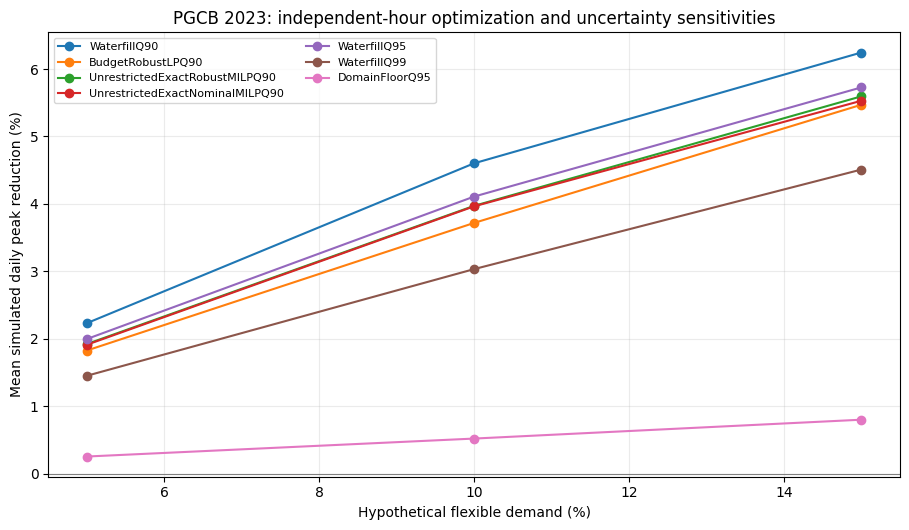

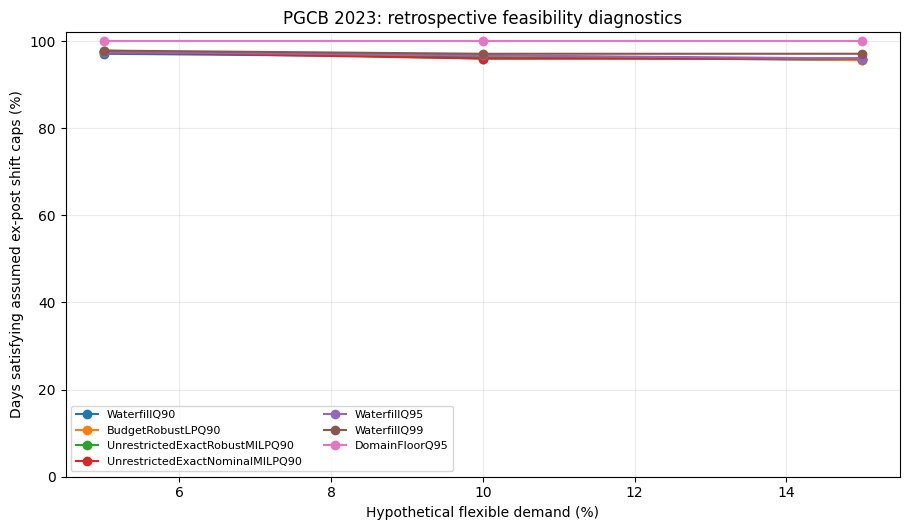

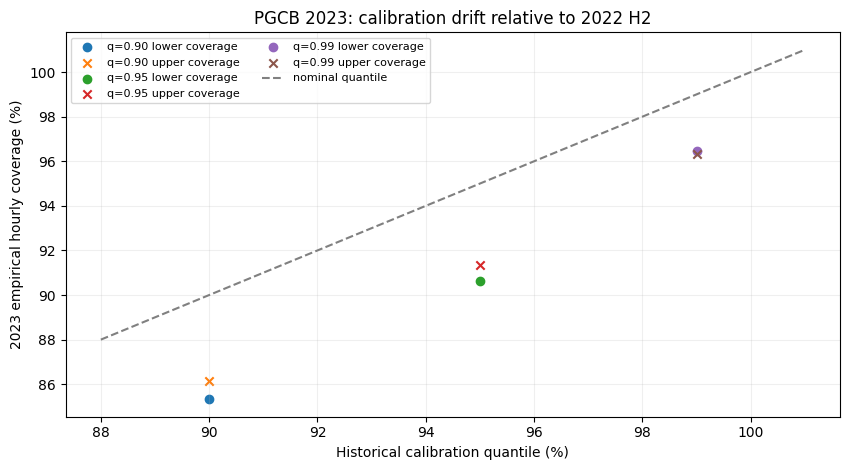

Saved three diagnostic PNG figures to: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase5_20261108T024327Z_6a8d61


In [ ]:
plot_methods=['WaterfillQ90','BudgetRobustLPQ90','UnrestrictedExactRobustMILPQ90',
              'UnrestrictedExactNominalMILPQ90','WaterfillQ95','WaterfillQ99','DomainFloorQ95']
fig,ax=plt.subplots(figsize=(9.2,5.4))
for method in plot_methods:
    sub=SUMMARY.loc[SUMMARY.method.eq(method)].sort_values('alpha')
    ax.plot(sub.alpha*100,sub.mean_peak_reduction_pct,marker='o',label=method)
ax.axhline(0,color='gray',lw=.8)
ax.set(xlabel='Hypothetical flexible demand (%)',
       ylabel='Mean simulated daily peak reduction (%)',
       title='PGCB 2023: independent-hour optimization and uncertainty sensitivities')
ax.grid(alpha=.25);ax.legend(fontsize=8,ncol=2);fig.tight_layout()
fig.savefig(OUT_DIR/'phase5_peak_reduction_2023.png',dpi=600)
plt.show()

fig,ax=plt.subplots(figsize=(9.2,5.4))
for method in plot_methods:
    sub=SUMMARY.loc[SUMMARY.method.eq(method)].sort_values('alpha')
    ax.plot(sub.alpha*100,sub.feasible_days_pct,marker='o',label=method)
ax.set(xlabel='Hypothetical flexible demand (%)',
       ylabel='Days satisfying assumed ex-post shift caps (%)',
       title='PGCB 2023: retrospective feasibility diagnostics',ylim=(0,102))
ax.grid(alpha=.25);ax.legend(fontsize=8,ncol=2);fig.tight_layout()
fig.savefig(OUT_DIR/'phase5_feasibility_2023.png',dpi=600)
plt.show()

fig,ax=plt.subplots(figsize=(8.6,4.8))
for q in MARGIN_QUANTILES:
    row=COVERAGE.loc[COVERAGE['quantile'].eq(q)].iloc[0]
    ax.scatter(100*q,row.lower_coverage_pct,label=f'q={q:.2f} lower coverage')
    ax.scatter(100*q,row.upper_coverage_pct,marker='x',label=f'q={q:.2f} upper coverage')
ax.plot([88,101],[88,101],ls='--',color='gray',label='nominal quantile')
ax.set(xlabel='Historical calibration quantile (%)',ylabel='2023 empirical hourly coverage (%)',
       title='PGCB 2023: calibration drift relative to 2022 H2')
ax.legend(fontsize=8,ncol=2);ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(OUT_DIR/'phase5_margin_coverage_2023.png',dpi=600)
plt.show()
print('Saved three diagnostic PNG figures to:',OUT_DIR)

## 16. Export audit protocol and all results

Save a full reproducibility manifest: original data checksum, exact train/calibration/evaluation windows, analysis limitations, method settings, solver versions and output files. A unique timestamped folder prevents overwriting earlier Colab runs. A ZIP archive collects the generated tables and figures for future GitHub and reviewer documentation; do **not** commit the full downloaded dataset into GitHub by default.

In [ ]:
PROTOCOL={
    'research_title':'An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids',
    'phase':'Phase 5 independent exact-MWh MILP and conservative feasibility diagnostics',
    'run_id':RUN_ID,
    'data_source':'UCI PGCB Hourly Generation Dataset (Bangladesh), DOI 10.24432/C59P6V, CC BY 4.0',
    'data_file_sha256':SOURCE_SHA256,
    'train':'Before 2022-07-01',
    'calibration':'2022-07-01 to 2022-12-31',
    'evaluation':'2023-01-01 to 2023-12-31 (exploratory and previously inspected)',
    'forecast_model':{'name':'Ridge','alpha':100.0,'features':FEATURES,
                      'exploratory_2023_mae_mw':evaluation_mae},
    'calendar_features_and_cleaning':'As in Phase 3; full 24-hour, on-hour, unique timestamp days only',
    'data_quality':DATA_QUALITY,
    'flexibility_levels':list(FLEX_LEVELS),
    'margin_quantiles':list(MARGIN_QUANTILES),
    'margin_hour_weight':HOUR_MARGIN_WEIGHT,
    'milp_solver':{'relative_gap':MIP_RELATIVE_GAP, 'time_limit_seconds':MIP_TIME_LIMIT_SECONDS,
                   'accept_status':'status 0 only (relative-gap certified)',
                   'donor_receiver_hours':'independently selected'},
    'domain_floor_mw':DOMAIN_FLOOR_MW,
    'domain_floor_caveat':'The 1000 MW floor follows a dataset inclusion rule, not a known physical lower demand bound.',
    'optimization_competitors':list(METHODS),
    'independent_exact_mwh_comparator':'MILP chooses its own donor/sink hours; source and receiver binary exclusivity; fixed candidate shifted MWh; same hourly planning caps',
    'budget_lp_comparator':'Independent hours, same hourly caps, total shifted MWh at most candidate budget; unused budget permitted',
    'bootstrap':'Calendar-week cluster resampling; descriptive exploratory 95-percent percentile intervals',
    'limitations':[
        '2023 already examined; not an independent final confirmation period.',
        'Hypothetical flexible loads are not observed customer capabilities.',
        'Retrospective feasibility diagnostics do not imply deployability.',
        'No proven finite-sample interval coverage under temporal dependence and distribution shifts.',
        'Conditional domain-floor feasibility is not a physical operational safety guarantee.',
        'LP/MILP results are optimal on specified prediction proxies, not on unknown realized demand.',
        'No avoided actual load-shedding, physical energy savings, network impacts, emissions, or costs are estimated.',
        'Originality of uncertainty-aware water filling is unproven; literature review needed.',
        'Repeated exploratory comparison selection and prior looks require independent evaluation.'
    ],
    'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
                'scipy':scipy.__version__,'sklearn':sklearn.__version__},
    'references':[
      {'title':'Residential Demand Side Management model, optimization and future perspective: A review',
       'doi':'10.1016/j.egyr.2022.02.300'},
      {'title':'A two-stage framework for demand-side management and energy savings of various buildings in multi smart grid using robust optimization algorithms',
       'doi':'10.1016/j.jobe.2022.104486'},
      {'title':'Distributionally robust optimization of home energy management system based on receding horizon optimization',
       'doi':'10.1007/s11708-020-0665-4'}],
}
(OUT_DIR/'phase5_protocol.json').write_text(json.dumps(PROTOCOL,indent=2))
archive_path=OUT_DIR/'phase5_outputs.zip'
with zipfile.ZipFile(archive_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for path in sorted(OUT_DIR.iterdir()):
        if path.is_file() and path!=archive_path:
            z.write(path,arcname=path.name)
required=['phase5_summary_2023.csv','phase5_daily_results_2023.csv',
          'phase5_weekly_bootstrap_2023.csv','phase5_protocol.json','phase5_outputs.zip']
assert all((OUT_DIR/file).exists() for file in required)
print('Phase 5 complete; files saved under:',OUT_DIR)
print('Primary outputs:',', '.join(required))
print('Research interpretation: exploratory comparison only; no novelty or operational guarantees claimed.')

Phase 5 complete; files saved under: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase5_20261108T024327Z_6a8d61
Primary outputs: phase5_summary_2023.csv, phase5_daily_results_2023.csv, phase5_weekly_bootstrap_2023.csv, phase5_protocol.json, phase5_outputs.zip
Research interpretation: exploratory comparison only; no novelty or operational guarantees claimed.
